# 02 — PDF Processing

**FinRAG learning series · Notebook 2 of 14**

## Learning objectives
1. Understand what is (and is not) inside a PDF: pages, a text layer, coordinates, fonts, images.
2. Use **PyMuPDF** to read metadata, text, words with coordinates, and render pages as images.
3. See why a naive `get_text()` is not enough for financial statements (two-page spreads, multi-column layout).
4. Run FinRAG's production `PdfParser` and understand its output: elements, period columns, page labels, tables.
5. Keep **source page numbers** (PDF page *and* printed page) for every value.

## Prerequisites
Notebook 01. A text-based PDF financial report in your documents folder. Saved outputs come from a public integrated annual
report (146 PDF pages, see `docs/evaluation/README.md`); the experiments use two of its statement pages.

## Concept: what a PDF contains
A PDF is a *page description*: it says "draw glyph X at position (x, y) with font F". There are no paragraphs, rows or columns —
only positioned characters (plus vector lines and images). Extracting a table therefore means **re-discovering** rows and columns
from coordinates.

* **Text layer**: present in digitally produced PDFs; absent in scans (→ OCR, notebook 05).
* **Coordinates**: points (1/72 inch), origin top-left in PyMuPDF; `page.rect` is the page size.
* **Fonts**: a font can map a glyph to any character code. That is why one report's ₹ sign is extracted as the letter "C".

### FinRAG's PDF workflow
```
PDF ─► per page: words + coordinates (PyMuPDF)          ─► OCR if no text layer (notebook 05)
     ─► split two-page spreads into left/right regions   ─► printed page label per region
     ─► ruled tables via find_tables() (quality-gated)
     ─► remaining words → visual lines → header lines (periods) / table rows / paragraphs
     ─► Elements with Location(page, page_label, half, bbox)
```

In [1]:
# Setup: make the production backend importable and keep secrets out of outputs
import sys, os
sys.path.insert(0, os.path.abspath("."))      # run notebooks from the notebooks/ folder
import finrag_nb as nb                          # helper: paths, safe settings, DB session
print("Backend package:", nb.BACKEND_DIR)
print("Documents folder:", nb.DOCS_DIR)

Backend package: /home/user/Ready_To_Deploy/backend
Documents folder: /opt/finrag_testdocs


## 1. Open the document and read metadata

In [2]:
import pymupdf

pdf_path = nb.doc_path("RIL-Integrated-Annual-Report-2024-25.pdf")   # replace with your own report
doc = pymupdf.open(pdf_path)
print("pages:", doc.page_count, "| encrypted:", doc.needs_pass)
print("metadata:", {k: v for k, v in doc.metadata.items() if v})
print("first page size (points):", doc[0].rect)

pages: 146 | encrypted: 0
metadata: {'format': 'PDF 1.4', 'creator': 'Adobe InDesign 20.4 (Windows)', 'producer': 'Adobe PDF Library 17.0', 'creationDate': "D:20250806193915+05'30'", 'modDate': "D:20250806194233+05'30'"}
first page size (points): Rect(0.0, 0.0, 595.2760009765625, 841.8900146484375)


## 2. Plain text extraction and its limits
`page.get_text()` returns text in content-stream order. Let us look at the consolidated balance sheet page
(PDF page 99 in this report — use any statement page from your own file).

In [3]:
PAGE = 99                       # 1-based PDF page number
page = doc[PAGE - 1]
print("page size:", page.rect, "-> landscape?", page.rect.width > page.rect.height)
txt = page.get_text()
print(len(txt), "characters; first 700:")
print(txt[:700])

page size: Rect(0.0, 0.0, 1190.550048828125, 841.8900146484375) -> landscape? True
3341 characters; first 700:
CONSOLIDATED FINANCIAL STATEMENTS
194
195
Reliance Industries Limited
Integrated Annual Report 2024-25
(C in crore)
Notes
As at
31st March, 2025
As at
31st March, 2024
Assets
Non-Current Assets
Property, Plant and Equipment
1
 6,83,102 
6,06,084
Spectrum
1
 1,47,122 
 69,852 
Other Intangible Assets
1
 1,44,639 
89,060
Goodwill
1
 24,530 
 14,989 
Capital Work-in-Progress
1
 1,69,710 
 1,52,382 
Spectrum Under Development
1
 54,176 
 1,29,602 
Other Intangible Assets Under Development
1
 38,472 
 56,871 
Financial Assets
 
 
Investments
2
 1,23,672 
 1,19,502 
	
Loans
3
 742 
 899 
 
Other Financial Assets
4
 6,088 
 2,622 
Deferred Tax Assets (Net)
5
 408 
 938 
Other Non-Current Assets
6
 


## 3. Seeing the page
Rendering the page shows *why* the text above looks jumbled: the PDF page is a **two-page spread** (two printed pages side by side).

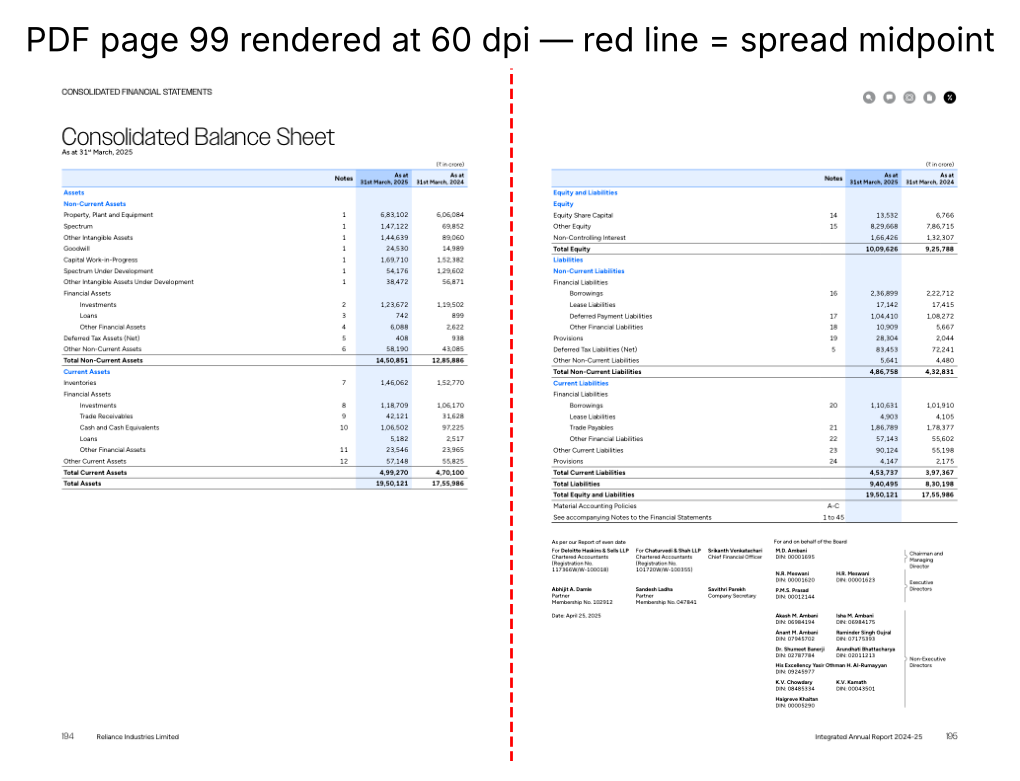

In [4]:
import matplotlib.pyplot as plt
import numpy as np

pix = page.get_pixmap(dpi=60)
img = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
plt.figure(figsize=(12, 4.5))
plt.imshow(img)
plt.axvline(pix.width / 2, color="red", linestyle="--", linewidth=1)
plt.title(f"PDF page {PAGE} rendered at 60 dpi — red line = spread midpoint")
plt.axis("off")
plt.show()

## 4. Words with coordinates
`get_text("words")` returns `(x0, y0, x1, y1, word, block, line, word_no)`. Coordinates are what let us rebuild rows and columns.

In [5]:
words = page.get_text("words")
print(len(words), "words on the page")
for w in words[:12]:
    print(f"x0={w[0]:7.1f} y0={w[1]:6.1f} x1={w[2]:7.1f}  {w[4]!r}")
mid = page.rect.width / 2
left = [w for w in words if w[2] <= mid]
right = [w for w in words if w[0] >= mid]
print(f"\nwords left of the midpoint: {len(left)}, right: {len(right)}")

438 words on the page
x0=   51.0 y0=  23.0 x1=  121.5  'CONSOLIDATED'
x0=  124.0 y0=  23.0 x1=  171.5  'FINANCIAL'
x0=  173.9 y0=  23.0 x1=  233.5  'STATEMENTS'
x0=   51.0 y0= 806.1 x1=   65.5  '194'
x0= 1125.5 y0= 806.1 x1= 1139.5  '195'
x0=   93.1 y0= 808.2 x1=  124.6  'Reliance'
x0=  126.6 y0= 808.2 x1=  163.2  'Industries'
x0=  165.1 y0= 808.2 x1=  193.0  'Limited'
x0=  966.4 y0= 808.3 x1= 1005.5  'Integrated'
x0= 1007.4 y0= 808.3 x1= 1033.2  'Annual'
x0= 1035.1 y0= 808.3 x1= 1060.7  'Report'
x0= 1062.6 y0= 808.3 x1= 1097.4  '2024-25'

words left of the midpoint: 154, right: 284


### Printed page numbers
Financial reports cite *printed* page numbers, which differ from PDF page numbers. FinRAG looks for a lone number near the outer
edge of the top/bottom band of each half. Here is the production helper:

In [6]:
from app.document_processing.parsers import pdf_parser as pp

W = [pp._Word(w[0], w[1], w[2], w[3], w[4]) for w in words]
r = page.rect
left_rect = pymupdf.Rect(r.x0, r.y0, mid, r.y1)
right_rect = pymupdf.Rect(mid, r.y0, r.x1, r.y1)
print("is spread:", pp._is_spread(page, W))
print("printed label (left half): ", pp._page_label([w for w in W if w.x1 <= mid], left_rect))
print("printed label (right half):", pp._page_label([w for w in W if w.x0 >= mid], right_rect))

is spread: True
printed label (left half):  194
printed label (right half): 195


## 5. Table extraction attempt 1 — PyMuPDF's ruled-table finder
`page.find_tables()` looks for ruling lines. Statements laid out with whitespace (no lines) often come out fragmented. FinRAG only
accepts a detected table if it passes a quality gate (`_table_quality_ok`).

In [7]:
tabs = page.find_tables().tables
print("tables found by find_tables():", len(tabs))
for t in tabs[:3]:
    rows = [[(c or "").strip() for c in row] for row in t.extract()]
    rows = [rw for rw in rows if any(rw)]
    print(f"\n bbox={tuple(round(v) for v in t.bbox)} rows={len(rows)} -> quality gate passed: {pp._table_quality_ok(rows)}")
    for rw in rows[:3]:
        print("   ", [c[:25].replace("\n", "⏎") for c in rw])

tables found by find_tables(): 2

 bbox=(51, 124, 544, 512) rows=25 -> quality gate passed: False
    ['', 'Notes', 'Asat⏎31st March 2025⏎,', 'Asat⏎31st March 2024⏎,']
    ['Assets⏎Non-Current Assets', '', '', '606084⏎, ,⏎69852⏎,⏎89060⏎']
    ['', '', '683102⏎, ,', '']

 bbox=(646, 124, 1140, 553) rows=26 -> quality gate passed: False
    ['', 'Notes', 'Asat⏎31st March 2025⏎,', 'Asat⏎31st March 2024⏎,']
    ['EquityandLiabilities⏎Equi', '', '', '6766⏎,⏎786715⏎, ,⏎132307⏎']
    ['', '', '13532⏎,', '']


## 6. Table extraction attempt 2 — FinRAG's layout-aware parser
The production `PdfParser` groups words into visual lines, detects **period header lines** (e.g. *"As at 31st March, 2025"*),
assigns each number to the nearest header column by x-position, and keeps row groups such as *"Current Liabilities"*.
We parse just pages 99–100 by copying them into a small temporary PDF.

In [8]:
import tempfile, time
from app.document_processing.parsers.pdf_parser import PdfParser

sub = pymupdf.open(); sub.insert_pdf(doc, from_page=98, to_page=99)
tmp = tempfile.NamedTemporaryFile(suffix=".pdf", delete=False).name
sub.save(tmp)
t = time.time()
parsed = PdfParser().parse(tmp)
print(f"parsed in {time.time() - t:.2f}s: {len(parsed.elements)} elements, {len(parsed.tables)} tables, warnings={parsed.warnings}")
from collections import Counter
print(Counter(e.kind for e in parsed.elements))

parsed in 1.35s: 142 elements, 4 tables, warnings=[]
Counter({'table_row': 91, 'paragraph': 43, 'heading': 8})


In [9]:
# Table rows with their period column, page, half of the spread and printed page label
for e in parsed.elements:
    if e.kind == "table_row" and e.label in ("Total Assets", "Borrowings", "Revenue from Operations", "Profit for the year"):
        loc = e.location
        print(f"p{loc.page} {loc.half:<5} printed {loc.page_label} | {nb.shorten(e.text, 110)}")
        print("      context:", [c for c in e.context if not c.startswith('group:')][-2:], "| groups:", [c[7:] for c in e.context if c.startswith('group:')][-2:])

p1 left  printed 194 | Total Assets | As at 31st March, 2025: 19,50,121 | As at 31st March, 2024: 17,55,986
      context: ['Consolidated Balance Sheet', '(C in crore)'] | groups: ['Current Assets', 'Financial Assets']
p1 right printed 195 | Borrowings | As at 31st March, 2025: 2,36,899 | As at 31st March, 2024: 2,22,712
      context: ['Consolidated Balance Sheet', '(C in crore)'] | groups: ['Non-Current Liabilities', 'Financial Liabilities']
p1 right printed 195 | Borrowings | As at 31st March, 2025: 1,10,631 | As at 31st March, 2024: 1,01,910
      context: ['Consolidated Balance Sheet', '(C in crore)'] | groups: ['Current Liabilities', 'Financial Liabilities']
p2 left  printed 196 | Revenue from Operations | 2024-25: 9,80,136 | 2023-24: 9,14,472
      context: ['Consolidated Statement of Profit and Loss', '(C in crore)'] | groups: ['Income']
p2 left  printed 196 | Profit for the year | 2024-25: 81,309 | 2023-24: 79,020
      context: ['Consolidated Statement of Profit and Loss', '(

Note that the page offset inside the temporary 2-page PDF is 1–2; when the real upload pipeline parses the full report the same
rows carry their true PDF page (99/100). Each value cell also has its own bounding box for precise highlighting.

In [10]:
for t in parsed.tables:
    print(f"table {t.table_id}: title={t.title!r} header={t.header} rows={len(t.rows)}")

table 0: title='(C in crore)' header=['Particulars', 'As at 31st March, 2025', 'As at 31st March, 2024'] rows=22
table 1: title='(C in crore)' header=['Particulars', 'As at 31st March, 2025', 'As at 31st March, 2024'] rows=27
table 2: title='(C in crore)' header=['Particulars', '2024-25', '2023-24'] rows=28
table 3: title='(C in crore)' header=['Particulars', '2024-25', '2023-24'] rows=14


## 7. Handling a multi-page report
Parsing the whole report applies the same steps to every page. Ruled-table detection is the slow part, so FinRAG only runs it on
pages that have enough numbers **and** enough ruling lines (`_worth_table_detection`). Let us measure on the first 20 pages.

In [11]:
sub = pymupdf.open(); sub.insert_pdf(doc, from_page=0, to_page=19)
tmp20 = tempfile.NamedTemporaryFile(suffix=".pdf", delete=False).name
sub.save(tmp20)
t = time.time()
p20 = PdfParser().parse(tmp20)
el = time.time() - t
print(f"20 pages parsed in {el:.1f}s ({el / 20:.2f}s/page): {len(p20.elements)} elements, {len(p20.tables)} tables, OCR pages: {p20.ocr_pages}")
gated = sum(pp._worth_table_detection(sub[i], [pp._Word(*w[:5]) for w in sub[i].get_text('words')]) for i in range(sub.page_count))
print(f"pages that passed the 'worth running find_tables' gate: {gated} of {sub.page_count}")

20 pages parsed in 11.7s (0.59s/page): 366 elements, 16 tables, OCR pages: []


pages that passed the 'worth running find_tables' gate: 14 of 20


## Interpretation
* Raw `get_text()` put both printed page numbers (194, 195) together at the top, placed note references (`1`, `2`, …) between
  labels and amounts, and separated every amount from its year header. Region splitting plus printed page labels fixes reading
  order and citations; header detection re-attaches each amount to its period.
* The ruled-table finder produced tables that fail the quality gate on these whitespace-aligned statements, so FinRAG's
  line-based parser handles them — and recovers the exact column headers.
* Row groups disambiguate repeated labels such as *Borrowings* (non-current vs current).

## Common errors and troubleshooting
| Symptom | Cause | Fix |
|---|---|---|
| Very little text / empty output | Scanned PDF (no text layer) | OCR — notebook 05 |
| Strange letters instead of symbols (₹ → "C") | Private font encoding | Cannot be recovered from the text layer; FinRAG marks currency *uncertain* |
| Numbers assigned to the wrong year | Header line not recognised | Inspect `_header_columns`; headers must contain ≥2 period tokens in separate columns |
| `ValueError: password-protected` | Encrypted PDF | Remove the password with the owner's permission first |
| Parsing is slow | Many ruled pages | Expected on CPU; the gate skips pages without numbers/rulings |

## Practical exercises
1. Pick a statement page in your own report. Is it a spread? What printed page labels does FinRAG detect?
2. Find a row label that occurs twice (e.g. *Borrowings*) and check which row group FinRAG attached to each.
3. Compare `page.get_text("text", sort=True)` with the parser output on the same page. What is lost?
4. Time a full parse of your report and compute seconds per page.

## Summary
You inspected a PDF at the level of words and coordinates, saw why spreads and whitespace tables break naive extraction, and ran the
production parser that FinRAG's upload pipeline uses, including its page-number preservation.

## Further learning
* PyMuPDF documentation: https://pymupdf.readthedocs.io/
* PDF reference (ISO 32000) overview: https://opensource.adobe.com/dc-acrobat-sdk-docs/
* FinRAG source: `backend/app/document_processing/parsers/pdf_parser.py`
* Next: **03 — DOCX processing**.